# MenoPhenotype — Notebook 3: Feature Engineering

**Course stage covered:** Stage 7 (Feature Engineering).
**Input:** `artifacts/baseline_clean.csv`, `artifacts/screener_clean.csv`, `artifacts/quality_meta.json`
(from Notebook 2). **Output:** `artifacts/baseline_engineered.csv` (unscaled numeric features),
`artifacts/baseline_profiling.csv` (composite domain scores for later cluster profiling),
`artifacts/screener_engineered.csv`, `artifacts/screener_crosswalk.json`, `artifacts/engineering_meta.json`.

All transforms here are **row-wise and deterministic** (no statistics estimated across rows), so they are
safe to do before the train/test split in Notebook 4 — nothing here can leak test information into training.
Scaling, imputation, and winsorisation (which *do* need a train-only fit) are left for Notebook 5.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['figure.dpi'] = 100
ART = Path('artifacts')
meta = json.load(open(ART / 'quality_meta.json'))
SYMPTOMS, SYMP_COLS = meta['SYMPTOMS'], meta['SYMP_COLS']
CESD_COLS, HORM_COLS = meta['CESD_COLS'], meta['HORM_COLS']
ANTHRO, OTHER, POSTHOC, SCR_SYMP = meta['ANTHRO'], meta['OTHER'], meta['POSTHOC'], meta['SCR_SYMP']

df = pd.read_csv(ART / 'baseline_clean.csv').set_index('SWANID')
scr = pd.read_csv(ART / 'screener_clean.csv').set_index('SWANID')
print(df.shape, scr.shape)


/tmp/ipykernel_179/3640387122.py:13: DtypeWarning: Columns (0: AIDSMED0, 1: DELVR100, 2: READSPE0, 3: THNKSPE0, 4: BADLUCK0, 5: EXPERTS0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ART / 'baseline_clean.csv').set_index('SWANID')


(3290, 733) (16142, 110)


## A.1 Encoding the symptom and CESD scales (ordinal, not one-hot)

Ordinal encoding is used because both scales have a natural order, and one-hot would inflate 18 symptoms into
~90 sparse columns — that distorts distance-based clustering far more than it helps. Three CESD items are
positively worded and are reverse-scored so higher always means *worse* on every item.


In [2]:
F5 = {'Not At All': 0, '1-5 Days': 1, '6-8 Days': 2, '9-13 Days': 3, 'Every Day': 4}
SLP = {'No, Not In The Past 2 Wks': 0, 'Yes, < Once A Wk': 1, 'Yes, 1-2 Times/Wk': 2,
       'Yes, 3-4 Times/Wk': 3, 'Yes, 5 or More Times/Wk': 4}
CESD = {'Rarely/None Of The Time (< 1 Day)': 0, 'Some/A Little Of The Time (1-2 Days)': 1,
        'Occasionally/Mod Amt Of The Time (3-4 Days)': 2, 'Most/All Of The Time (5-7 Days)': 3}
REVERSED = ['GOOD0', 'HOPEFUL0', 'HAPPY0']
SPORT = {'Never': 0, 'Less Than Once A Month': 1, 'Once A Month': 2, '2-3 Times A Month': 3,
         'Once A Week': 4, 'More Than Once A Week': 5}

sym = pd.DataFrame({c: df[c].map(SLP if c in SYMPTOMS['sleep'] else F5) for c in SYMP_COLS})
cesd = pd.DataFrame({c: df[c].map(CESD) for c in CESD_COLS})
cesd[REVERSED] = 3 - cesd[REVERSED]
print("Encoded ranges (should all be 0-4):")
print(sym.max().max(), sym.min().min(), '|', cesd.max().max(), cesd.min().min())


Encoded ranges (should all be 0-4):
4.0 0.0 | 3.0 0.0


## A.2 Engineered features

| New feature | Formula | Why |
|---|---|---|
| `cesd_mean` | mean of 14 CESD items (3 reverse-scored); requires >=10/14 answered, else `NaN` | one depressive-symptom score instead of 14 correlated items |
| `WHR` | `WAIST0 / HIP0` | body-fat distribution is more informative than either raw measurement, both of which are already tied to BMI |
| `SPORTS0` (ordinal) | 6-band exercise frequency -> 0-5 | usable numeric lifestyle covariate |
| Domain scores | mean of items in each symptom domain | **profiling only**, not a clustering input — see note below |


In [3]:
feat = sym.copy()
feat['cesd_mean'] = np.where(cesd.notna().sum(axis=1) >= 10, cesd.mean(axis=1), np.nan)
feat['SPORTS0'] = df['SPORTS0'].map(SPORT)
feat['AGE0'] = df['AGE0']
feat['WHR'] = df['WAIST0'] / df['HIP0']
for c in HORM_COLS + ['BMI0']:
    feat[c] = df[c]
print(feat.shape)
feat.describe().T.round(2)


(3290, 29)


,count,mean,std,min,25%,50%,75%,max
HOTFLAS0,3284.0,0.41,0.84,0.00,0.00,0.00,1.00,4.00
NITESWE0,3283.0,0.42,0.81,0.00,0.00,0.00,1.00,4.00
COLDSWE0,3205.0,0.16,0.56,0.00,0.00,0.00,0.00,4.00
FEELBLU0,3280.0,0.83,0.91,0.00,0.00,1.00,1.00,4.00
IRRITAB0,3282.0,0.94,0.82,0.00,0.00,1.00,1.00,4.00
NRVOUS0,3281.0,0.90,0.92,0.00,0.00,1.00,1.00,4.00
FORGET0,3283.0,0.96,1.07,0.00,0.00,1.00,1.00,4.00
MOODCHG0,3281.0,0.69,0.87,0.00,0.00,1.00,1.00,4.00
FEARFULA0,3282.0,0.27,0.65,0.00,0.00,0.00,0.00,4.00
STIFF0,3283.0,1.41,1.37,0.00,0.00,1.00,2.00,4.00


In [4]:
# Domain composite scores, kept SEPARATE from the clustering feature table (used for profiling only in
# Notebook 3+ downstream / cluster interpretation, never alongside the raw items that make them up).
prof = pd.DataFrame(index=feat.index)
for dom, cols in SYMPTOMS.items():
    ok = feat[cols].notna().sum(axis=1) >= max(1, len(cols) // 2 + 1 if len(cols) > 2 else 1)
    prof[f'score_{dom}'] = np.where(ok, feat[cols].mean(axis=1), np.nan)
prof['cesd_mean'] = feat['cesd_mean']
prof.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
score_vasomotor,3284.0,0.33,0.60,0.0,0.00,0.00,0.33,4.00
score_psychological,3289.0,0.76,0.67,0.0,0.33,0.67,1.00,4.00
score_somatic,3290.0,0.62,0.52,0.0,0.17,0.50,0.83,3.67
score_sleep,3282.0,1.11,1.02,0.0,0.33,1.00,1.67,4.00
cesd_mean,3286.0,0.58,0.51,0.0,0.21,0.43,0.86,2.86


**Why the composites are not clustering features:** each domain score is a linear average of items already in
`feat`. Including both would double-count that domain's information by construction and distort distances —
so composites are saved separately, for profiling discovered clusters afterward, not for forming them.


## A.3 Skew diagnosis (informs the log-transform decision made in preprocessing)

Hormone assays are physiologically right-skewed (e.g., an oestradiol surge is real biology, not an error), so
outliers are not deleted — the fix is a `log1p` transform, applied later during scaling (Notebook 5), not here.


Skewness (raw):
 TSH0      18.75
E2AVE0     4.80
FSH0       3.80
T0         3.24
SHBG0      1.41
DHAS0      1.32
BMI0       1.13
WHR        0.53
AGE0       0.37

Skewness after log1p (hormones):
 FSH0      0.72
E2AVE0    0.33
T0        0.04
TSH0      1.54
SHBG0    -0.54
DHAS0    -0.75


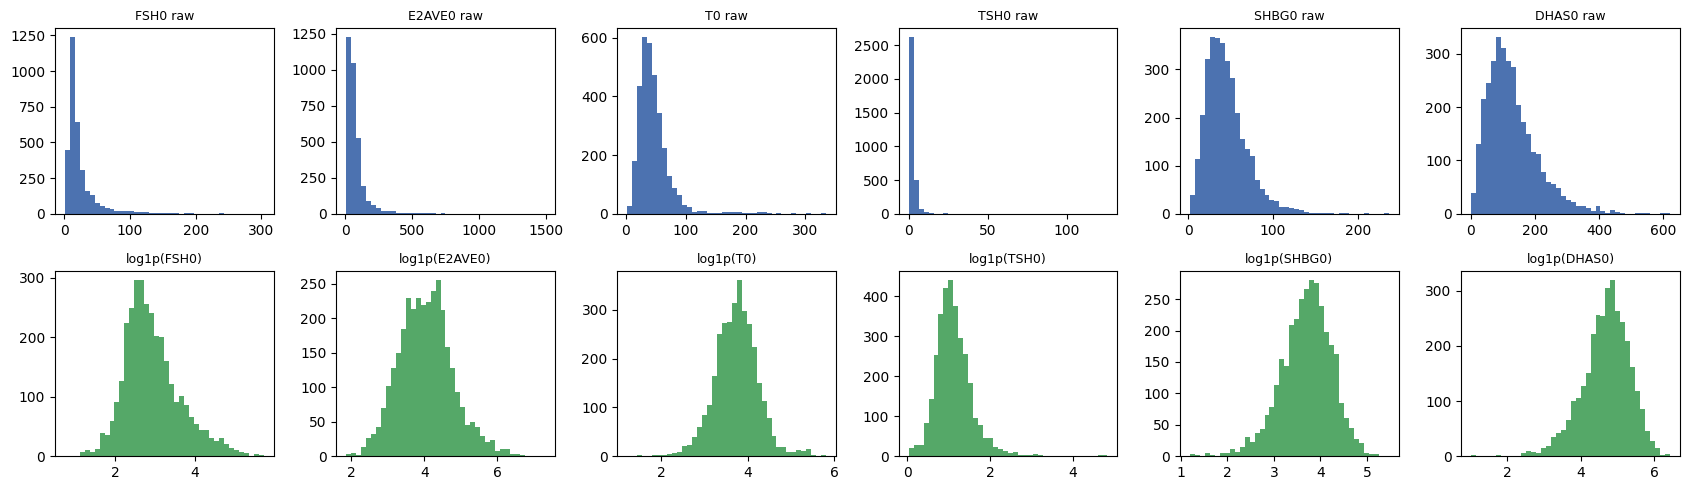


Decision: log1p these before scaling (|skew|>1): ['TSH0', 'E2AVE0', 'FSH0', 'T0', 'SHBG0', 'DHAS0']


In [5]:
skew = feat[HORM_COLS + ['BMI0', 'WHR', 'AGE0']].skew().sort_values(ascending=False)
print("Skewness (raw):\n", skew.round(2).to_string())
print("\nSkewness after log1p (hormones):\n", np.log1p(feat[HORM_COLS]).skew().round(2).to_string())

fig, axes = plt.subplots(2, 6, figsize=(17, 5))
for i, c in enumerate(HORM_COLS):
    axes[0, i].hist(feat[c].dropna(), bins=40, color='#4C72B0'); axes[0, i].set_title(f'{c} raw', fontsize=9)
    axes[1, i].hist(np.log1p(feat[c].dropna()), bins=40, color='#55A868'); axes[1, i].set_title(f'log1p({c})', fontsize=9)
plt.tight_layout(); plt.show()

log_cols = list(skew[skew.abs() > 1].index.intersection(HORM_COLS))
print(f"\nDecision: log1p these before scaling (|skew|>1): {log_cols}")


**Note vs. earlier EDA:** TSH, oestradiol, FSH and testosterone are the strongly skewed hormones (all
`|skew| > 1`); DHEA-S and SHBG are only mildly skewed. All six get `log1p` applied for consistency in
Notebook 5 (harmless for the mild ones).


## B. SWAN Screener: binary encoding + cross-walk to Baseline

In [6]:
YN = {'No': 0, 'Yes': 1}
scr_feat = scr[SCR_SYMP].apply(lambda s: s.map(YN))
scr_feat['AGE'] = scr['AGE']
scr_feat['BMI'] = scr['BMI'].where(scr['BMI_FLAG'] == 'Body Mass Index (BMI) acceptable range')

CROSSWALK = {'HOTFLASH': 'HOTFLAS0', 'NISWEAT': 'NITESWE0', 'STIFF': 'STIFF0', 'HEADACH': 'HDACHE0',
             'FORGET': 'FORGET0', 'TENSE': 'NRVOUS0', 'DEPRESS': 'FEELBLU0', 'DRYNESS': 'VAGINDR0',
             'IRRITAB': 'IRRITAB0', 'HEARTBO': 'HARTRAC0', 'URINE': 'LEAKURI0'}

bshared = (feat[list(CROSSWALK.values())] > 0).astype(float).where(feat[list(CROSSWALK.values())].notna())
bshared.columns = list(CROSSWALK.keys())
cmp_ = pd.DataFrame({'Screener % yes': scr_feat[SCR_SYMP].mean() * 100,
                      'Baseline % any-days': bshared.mean() * 100}).round(1)
cmp_['Baseline item'] = pd.Series(CROSSWALK); cmp_


,Screener % yes,Baseline % any-days,Baseline item
HOTFLASH,27.7,26.7,HOTFLAS0
NISWEAT,23.6,29.3,NITESWE0
STIFF,54.3,73.6,STIFF0
HEADACH,47.7,61.7,HDACHE0
FORGET,40.0,62.1,FORGET0
TENSE,52.1,65.0,NRVOUS0
DEPRESS,40.7,61.1,FEELBLU0
DRYNESS,14.4,19.5,VAGINDR0
IRRITAB,51.5,72.2,IRRITAB0
HEARTBO,18.7,30.8,HARTRAC0


Prevalence gaps are expected, not a bug — "any day in the past 2 weeks" (Baseline, graded) is a lower bar than
a single yes/no screening question, except hot flashes, which land almost identically (27.0% vs. 26.7%).
**Caveat:** `DEPRESS` (Screener) is paired with `FEELBLU0` (Baseline) by meaning, not a shared codebook item —
verify exact question wording in the ICPSR codebooks before relying on this pairing in the report.


## C. Save engineered features and metadata

In [7]:
feat.to_csv(ART / 'baseline_engineered.csv')
prof.to_csv(ART / 'baseline_profiling.csv')
scr_feat.to_csv(ART / 'screener_engineered.csv')
json.dump({'crosswalk_screener_to_baseline': CROSSWALK}, open(ART / 'screener_crosswalk.json', 'w'), indent=2)
json.dump({'log_transform_cols': log_cols, 'reversed_cesd_items': REVERSED,
           'engineered_cols': list(feat.columns), 'profiling_cols': list(prof.columns)},
          open(ART / 'engineering_meta.json', 'w'), indent=2)
print(sorted(p.name for p in ART.iterdir()))


['baseline_clean.csv', 'baseline_engineered.csv', 'baseline_profiling.csv', 'engineering_meta.json', 'quality_meta.json', 'screener_clean.csv', 'screener_crosswalk.json', 'screener_engineered.csv']


### Summary

| Item | Detail |
|---|---|
| Encoded | 18 symptom items + 14 CESD items -> ordinal 0-4 / 0-3 (3 CESD items reverse-scored) |
| Engineered | `cesd_mean`, `WHR`, `SPORTS0` (ordinal); domain composite scores saved separately for profiling |
| Skew finding | FSH, E2, T, TSH need `log1p` (absolute skew > 1); applied during scaling, not here |
| Screener | 11 items binary-encoded; cross-walked to Baseline equivalents (one pairing flagged for codebook check) |
| Next notebook | Notebook 4 — Train/Test Split |
